# CSE-438 Image Processing — Part B: Self-Supervised Learning

### Data Prep Notebook — Split Role Mapping & Loader Preparation (Task A)

**Course:** CSE-438 (Digital Image Processing) — East West University, Summer 2026
**Dataset:** Weedy Rice RGBMS Dataset (WeedyRice-RGBMS-DB)
**Platform:** Kaggle

---

### Notebook Objective

This notebook implements **Task A** of the Part B assignment: it loads the identical
leakage-safe train/validation/test split produced in Part A (Notebook 0), maps each
split onto its new Part-B role, verifies the split is unmodified and leakage-free,
builds the per-role data loaders, saves the split file lists as artifacts for every
downstream SSL-method notebook to reuse, and produces the required sanity-check
visualizations.

| Part-A Split | New Role in Part B | Notes |
|---|---|---|
| **Train** | Unlabelled SSL pretraining corpus (Task B) | Every image in the Part-A training split is used, images only — masks are ignored during pretraining. |
| **Validation** | Labelled fine-tuning set (Task D) | Every image in the Part-A validation split is used with its mask as the small labelled training data for supervised fine-tuning. |
| **Test** | Downstream monitoring + final evaluation (Tasks D & E) | Used to monitor fine-tuning progress and select the best checkpoint, then again to report final test-set metrics (see caveat in Section 2 of the assignment — the double role is a deliberate, documented simplification). |

This role mapping is reused identically by all four SSL method notebooks (SimCLR,
BYOL, MAE, DINOv2) so the label-efficiency comparison in the Final Comparison
notebook is apples-to-apples.

## Cell 1 — Environment Setup & Dataset Discovery

**Objective:** Import dependencies, fix random seeds for reproducibility, and
auto-discover the dataset root under `/kaggle/input/`. This mirrors the setup used
in Notebook 0 (Part-A EDA) and Notebook 1/2 of Part B, so every notebook in the
project starts from an identical, reproducible environment.

In [1]:
# ============================================================
# CELL 1 : Environment Setup & Dataset Discovery
# ============================================================

import os
import random
import json
from pathlib import Path
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

try:
    import torch
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
except ImportError:
    pass

print("=" * 60)
print("SEED FIXED:", SEED)
print("=" * 60)

# ---------------------------------------------------------------------------
# Auto-discover dataset root (same logic as Notebook 0 / Notebook 1)
# ---------------------------------------------------------------------------
def find_dataset_root():
    base = Path("/kaggle/input")
    if not base.exists():
        return None
    for p in base.rglob("WeedyRice-RGBMS-DB"):
        if p.is_dir():
            return p
    return None

DATASET_ROOT = find_dataset_root()
if DATASET_ROOT is None:
    # Fallback to the known path used across Notebook 0 / 1 / 2
    DATASET_ROOT = Path("/kaggle/input/datasets/subbhaa/weedy-rice-rgbms-dataset/WeedyRice-RGBMS-DB")

RGB_PATH = DATASET_ROOT / "RGB"
MASK_PATH = DATASET_ROOT / "Masks"

OUTPUT_DIR = Path("/kaggle/working")
OUTPUT_DIR.mkdir(exist_ok=True)

print("Dataset root :", DATASET_ROOT)
print("Exists       :", DATASET_ROOT.exists())
print("RGB folder   :", RGB_PATH, "| exists:", RGB_PATH.exists())
print("Masks folder :", MASK_PATH, "| exists:", MASK_PATH.exists())

SEED FIXED: 42
Dataset root : /kaggle/input/datasets/subbhaa/weedy-rice-rgbms-dataset/WeedyRice-RGBMS-DB
Exists       : True
RGB folder   : /kaggle/input/datasets/subbhaa/weedy-rice-rgbms-dataset/WeedyRice-RGBMS-DB/RGB | exists: True
Masks folder : /kaggle/input/datasets/subbhaa/weedy-rice-rgbms-dataset/WeedyRice-RGBMS-DB/Masks | exists: True


## Cell 2 — Load the Official Part-A Split Files (Unmodified)

**Objective:** Load `train_list.txt`, `val_list.txt`, and `test_list.txt` exactly as
produced in Part-A Notebook 0 — no re-splitting, no re-shuffling. This is the same
split-loading logic used independently in Part-B Notebook 1 (Cell 3) and Notebook 2
(Cell 5); consolidating it here gives the project a single canonical reference point,
while each method notebook continues to read the same official files directly from
the dataset root — so there is no risk of the split ever drifting between notebooks.

In [2]:
# ============================================================
# CELL 2 : Load Official Train / Val / Test Splits
# ============================================================

def load_split_file(path: Path):
    """Load a split file (one filename stem per line), matching Notebook 0 / Notebook 2."""
    with open(path, "r") as f:
        return [Path(line.strip()).stem for line in f if line.strip()]

TRAIN_LIST = DATASET_ROOT / "train_list.txt"
VAL_LIST   = DATASET_ROOT / "val_list.txt"
TEST_LIST  = DATASET_ROOT / "test_list.txt"

train_stems = load_split_file(TRAIN_LIST)
val_stems   = load_split_file(VAL_LIST)
test_stems  = load_split_file(TEST_LIST)

print("=" * 60)
print("OFFICIAL SPLIT FILES LOADED (Part-A, unmodified)")
print("=" * 60)
print(f"Train      : {len(train_stems)} images  -> Part-B role: UNLABELLED SSL pretraining corpus")
print(f"Validation : {len(val_stems)} images  -> Part-B role: LABELLED fine-tuning set")
print(f"Test       : {len(test_stems)} images  -> Part-B role: downstream monitoring + final evaluation")
print(f"Total      : {len(train_stems) + len(val_stems) + len(test_stems)} images")

OFFICIAL SPLIT FILES LOADED (Part-A, unmodified)
Train      : 438 images  -> Part-B role: UNLABELLED SSL pretraining corpus
Validation : 148 images  -> Part-B role: LABELLED fine-tuning set
Test       : 148 images  -> Part-B role: downstream monitoring + final evaluation
Total      : 734 images


## Cell 3 — Leakage Verification

**Objective:** Confirm the three splits share zero images in common. This repeats
the check already performed in Part-A Notebook 0 (Task B) to make the guarantee
explicit for Part B as well — since Part B reuses the identical split, a passing
result here confirms no leakage was introduced when the roles were reassigned.

In [3]:
# ============================================================
# CELL 3 : Leakage-Safe Split Verification
# ============================================================

train_set, val_set, test_set = set(train_stems), set(val_stems), set(test_stems)

overlap_train_val  = train_set & val_set
overlap_train_test = train_set & test_set
overlap_val_test   = val_set & test_set

print("=" * 60)
print("LEAKAGE VERIFICATION")
print("=" * 60)
print(f"Train ∩ Validation : {len(overlap_train_val)} overlapping images")
print(f"Train ∩ Test       : {len(overlap_train_test)} overlapping images")
print(f"Validation ∩ Test  : {len(overlap_val_test)} overlapping images")

assert not overlap_train_val,  "Leakage detected between train and validation!"
assert not overlap_train_test, "Leakage detected between train and test!"
assert not overlap_val_test,   "Leakage detected between validation and test!"

print("\nResult: PASSED — no leakage across train / validation / test splits.")

LEAKAGE VERIFICATION
Train ∩ Validation : 0 overlapping images
Train ∩ Test       : 0 overlapping images
Validation ∩ Test  : 0 overlapping images

Result: PASSED — no leakage across train / validation / test splits.


## Cell 4 — Build File Path Maps & Verify Image–Mask Pairing

**Objective:** Map every split's filename stems to their absolute RGB (and, for
validation/test, mask) paths, and confirm every referenced file actually exists on
disk before any loader is built.

In [4]:
# ============================================================
# CELL 4 : Build Path Maps & Verify Pairing
# ============================================================

def build_path_map(directory: Path, extensions):
    path_map = {}
    for ext in extensions:
        for p in directory.glob(f"*{ext}"):
            path_map[p.stem] = p
    return path_map

rgb_map  = build_path_map(RGB_PATH, (".JPG", ".jpg", ".png"))
mask_map = build_path_map(MASK_PATH, (".png",))

def verify_split(stems, split_name, require_mask):
    missing_rgb, missing_mask = [], []
    for s in stems:
        if s not in rgb_map:
            missing_rgb.append(s)
        if require_mask and s not in mask_map:
            missing_mask.append(s)
    print(f"[{split_name}] missing RGB: {len(missing_rgb)} | missing mask: {len(missing_mask) if require_mask else 'n/a (unlabelled)'}")
    return missing_rgb, missing_mask

print("=" * 60)
print("IMAGE / MASK PAIRING VERIFICATION")
print("=" * 60)
verify_split(train_stems, "Train (unlabelled)", require_mask=False)
verify_split(val_stems,   "Validation (labelled fine-tune)", require_mask=True)
verify_split(test_stems,  "Test (monitor + eval)", require_mask=True)

IMAGE / MASK PAIRING VERIFICATION
[Train (unlabelled)] missing RGB: 0 | missing mask: n/a (unlabelled)
[Validation (labelled fine-tune)] missing RGB: 0 | missing mask: 0
[Test (monitor + eval)] missing RGB: 0 | missing mask: 0


([], [])

## Cell 5 — Save Split Artifacts for Downstream Notebooks

**Objective:** Persist the three split file lists (and the role-mapping) as plain
artifacts in `/kaggle/working`, so this notebook's output can be attached as a
Kaggle dataset and referenced explicitly by every SSL-method notebook — matching the
assignment's requirement to "save a copy of the index/file lists as artifacts... for
the other notebooks to reuse."

In [5]:
# ============================================================
# CELL 5 : Save Split Artifacts
# ============================================================

artifact = {
    "dataset_root": str(DATASET_ROOT),
    "roles": {
        "train": "unlabelled_ssl_pretraining_corpus",
        "validation": "labelled_finetuning_set",
        "test": "downstream_monitoring_and_final_evaluation",
    },
    "counts": {
        "train": len(train_stems),
        "validation": len(val_stems),
        "test": len(test_stems),
    },
    "train_stems": train_stems,
    "val_stems": val_stems,
    "test_stems": test_stems,
}

artifact_path = OUTPUT_DIR / "part_b_split_roles.json"
with open(artifact_path, "w") as f:
    json.dump(artifact, f, indent=2)

print("Saved split-role artifact ->", artifact_path)
print("File size:", artifact_path.stat().st_size, "bytes")
print("\nAttach this notebook's output as a Kaggle dataset so every SSL-method")
print("notebook can (optionally) load 'part_b_split_roles.json' directly, in")
print("addition to reading the same official split files from the dataset root.")

Saved split-role artifact -> /kaggle/working/part_b_split_roles.json
File size: 62800 bytes

Attach this notebook's output as a Kaggle dataset so every SSL-method
notebook can (optionally) load 'part_b_split_roles.json' directly, in
addition to reading the same official split files from the dataset root.


## Cell 6 — Validation & Test Loader Pipelines

**Objective:** Define two of the three Task-A loader pipelines:

1. **Validation split** — synchronized image+mask augmentation (reused from Part A),
   for the labelled fine-tuning loader used in Task D.
2. **Test split** — deterministic resize/normalize only, no augmentation, for
   monitoring and final evaluation.

(The third pipeline — train split, images-only — comes next in Cell 6b, since it
needs its own explanation.)

In [6]:
# ============================================================
# CELL 6 : Validation & Test Loader Pipelines (Part-A Consistent)
# ============================================================
import albumentations as A
from albumentations.pytorch import ToTensorV2

# NOTE: This reuses Part-A's exact augmentation pipeline (Notebook 0, Task C.2),
# applied here to the validation split since it now serves the "labelled
# fine-tuning" (training) role in Part B, per the assignment's Task A
# instruction to "reuse your Part-A augmentation pipeline."

IMAGE_SIZE = 512  # matches Part-A's original augmentation pipeline (Notebook 0, Task C)
MEAN = [0.374262, 0.468811, 0.210075]   # dataset-specific stats (Notebook 0, Section 11)
STD  = [0.152524, 0.150293, 0.136316]

# ---------------------------------------------------------------------------
# 1. Validation split — Part-A's train_transform (labelled fine-tune role)
# ---------------------------------------------------------------------------
val_finetune_transform = A.Compose([
    A.Resize(height=IMAGE_SIZE, width=IMAGE_SIZE),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.2),
    A.RandomRotate90(p=0.5),
    A.RandomBrightnessContrast(
        brightness_limit=0.2,
        contrast_limit=0.2,
        p=0.5
    ),
    A.GaussianBlur(
        blur_limit=(3, 5),
        p=0.2
    ),
    A.Normalize(mean=MEAN, std=STD),
    ToTensorV2(),
])

# ---------------------------------------------------------------------------
# 2. Test split — Part-A's valid_transform (deterministic, no augmentation)
# ---------------------------------------------------------------------------
test_eval_transform = A.Compose([
    A.Resize(height=IMAGE_SIZE, width=IMAGE_SIZE),
    A.Normalize(mean=MEAN, std=STD),
    ToTensorV2(),
])

print("Validation (labelled fine-tune) pipeline : ready — Part-A train_transform reused")
print("Test (monitor + eval) pipeline           : ready — Part-A valid_transform reused, deterministic")

Validation (labelled fine-tune) pipeline : ready — Part-A train_transform reused
Test (monitor + eval) pipeline           : ready — Part-A valid_transform reused, deterministic


## Cell 6b — Train Split: Per-Method SSL View-Generation Pipelines

**Objective:** Define the train-split "images only, no masks" view generator for
**all four SSL methods**, as required by the assignment's Data Prep contents list
("per-method augmentation pipelines"). Each method's pretext task needs a different
view-generation strategy — full pretraining model logic still lives in each
method's own notebook; only the input augmentation/view pipeline is defined here.

In [7]:
# ============================================================
# CELL 6b : Train Split — Per-Method SSL View-Generation Pipelines
# ============================================================
import torchvision.transforms as T

def load_train_image(stem):
    """Shared across all SSL methods: load a train-split image, no mask."""
    return Image.open(rgb_map[stem]).convert("RGB")

# ---------------------------------------------------------------------------
# SimCLR
# ---------------------------------------------------------------------------
simclr_transform = T.Compose([
    T.RandomResizedCrop(
        224,
        scale=(0.70, 1.00),
        antialias=True
    ),
    T.RandomHorizontalFlip(p=0.5),

    T.RandomApply([
        T.ColorJitter(
            brightness=0.25,
            contrast=0.25
        )
    ], p=0.60),

    T.RandomApply([
        T.GaussianBlur(
            kernel_size=15,
            sigma=(0.1, 1.5)
        )
    ], p=0.30),

    T.ToTensor(),
    T.Normalize(mean=MEAN, std=STD),
])

def simclr_two_views(stem):
    img = load_train_image(stem)
    return simclr_transform(img), simclr_transform(img)

# ---------------------------------------------------------------------------
# BYOL — two augmented views (online vs. target branch)
# ---------------------------------------------------------------------------
byol_transform_1 = T.Compose([
    T.RandomResizedCrop(224, scale=(0.2, 1.0)),
    T.RandomHorizontalFlip(p=0.5),
    T.ColorJitter(0.4, 0.4, 0.2, 0.1),
    T.RandomGrayscale(p=0.2),
    T.GaussianBlur(kernel_size=23, sigma=(0.1, 2.0)),
    T.ToTensor(),
    T.Normalize(mean=MEAN, std=STD),
])
byol_transform_2 = T.Compose([
    T.RandomResizedCrop(224, scale=(0.2, 1.0)),
    T.RandomHorizontalFlip(p=0.5),
    T.ColorJitter(0.4, 0.4, 0.2, 0.1),
    T.RandomGrayscale(p=0.1),
    T.ToTensor(),
    T.Normalize(mean=MEAN, std=STD),
])

def byol_two_views(stem):
    img = load_train_image(stem)
    return byol_transform_1(img), byol_transform_2(img)

# ---------------------------------------------------------------------------
# MAE — one view; patch masking (~75%) applied inside the MAE model/notebook
# ---------------------------------------------------------------------------
mae_transform = T.Compose([
    T.RandomResizedCrop(224, scale=(0.4, 1.0)),
    T.RandomHorizontalFlip(p=0.5),
    T.ToTensor(),
    T.Normalize(mean=MEAN, std=STD),
])

def mae_view(stem):
    img = load_train_image(stem)
    return mae_transform(img)

# ---------------------------------------------------------------------------
# DINOv2 — multi-crop: global crops (large) + local crops (small, high distortion)
# ---------------------------------------------------------------------------
dino_global_transform = T.Compose([
    T.RandomResizedCrop(224, scale=(0.4, 1.0)),
    T.RandomHorizontalFlip(p=0.5),
    T.ColorJitter(0.4, 0.4, 0.2, 0.1),
    T.RandomGrayscale(p=0.2),
    T.ToTensor(),
    T.Normalize(mean=MEAN, std=STD),
])
dino_local_transform = T.Compose([
    T.RandomResizedCrop(96, scale=(0.05, 0.4)),
    T.RandomHorizontalFlip(p=0.5),
    T.ColorJitter(0.4, 0.4, 0.2, 0.1),
    T.RandomGrayscale(p=0.2),
    T.ToTensor(),
    T.Normalize(mean=MEAN, std=STD),
])

def dino_multi_crop(stem, n_global=2, n_local=4):
    img = load_train_image(stem)
    globals_ = [dino_global_transform(img) for _ in range(n_global)]
    locals_ = [dino_local_transform(img) for _ in range(n_local)]
    return globals_, locals_

print("Train (unlabelled SSL corpus) view-generators ready for all four methods:")
print("  SimCLR : simclr_two_views(stem)  -> (view1, view2)")
print("  BYOL   : byol_two_views(stem)    -> (view1, view2)")
print("  MAE    : mae_view(stem)          -> single view (masking done in MAE notebook)")
print("  DINOv2 : dino_multi_crop(stem)   -> (2 global crops, 4 local crops)")

Train (unlabelled SSL corpus) view-generators ready for all four methods:
  SimCLR : simclr_two_views(stem)  -> (view1, view2)
  BYOL   : byol_two_views(stem)    -> (view1, view2)
  MAE    : mae_view(stem)          -> single view (masking done in MAE notebook)
  DINOv2 : dino_multi_crop(stem)   -> (2 global crops, 4 local crops)


## Cell 6c — Dataset Classes & DataLoaders (All Splits, All Methods)

**Objective:** Build actual PyTorch `Dataset`/`DataLoader` objects for every split
and method — not just standalone transform functions — and verify output batch
shapes, per Task A's explicit loader requirement.

In [8]:
# ============================================================
# CELL 6c : Dataset Classes & DataLoaders
# ============================================================
from torch.utils.data import Dataset, DataLoader

class SSLImageDataset(Dataset):
    """Unlabelled train-split dataset: images only, no masks."""
    def __init__(self, stems, view_fn):
        self.stems = stems
        self.view_fn = view_fn
    def __len__(self):
        return len(self.stems)
    def __getitem__(self, idx):
        return self.view_fn(self.stems[idx])


class SegmentationDataset(Dataset):
    """Labelled dataset: image + mask, synchronized Albumentations transform."""
    def __init__(self, stems, transform):
        self.stems = stems
        self.transform = transform
    def __len__(self):
        return len(self.stems)
    def __getitem__(self, idx):
        stem = self.stems[idx]
        image = np.array(Image.open(rgb_map[stem]).convert("RGB"))
        mask = np.array(Image.open(mask_map[stem]).convert("L"))
        mask = np.where(mask > 0, 1, 0).astype(np.uint8)
        aug = self.transform(image=image, mask=mask)
        return aug["image"], aug["mask"].long(), stem


BATCH_SIZE = 8

simclr_train_loader = DataLoader(SSLImageDataset(train_stems, simclr_two_views), batch_size=BATCH_SIZE, shuffle=True)
byol_train_loader   = DataLoader(SSLImageDataset(train_stems, byol_two_views),   batch_size=BATCH_SIZE, shuffle=True)
mae_train_loader    = DataLoader(SSLImageDataset(train_stems, mae_view),         batch_size=BATCH_SIZE, shuffle=True)
dino_train_loader   = DataLoader(SSLImageDataset(train_stems, dino_multi_crop),  batch_size=BATCH_SIZE, shuffle=True)

val_finetune_loader = DataLoader(SegmentationDataset(val_stems, val_finetune_transform), batch_size=BATCH_SIZE, shuffle=True)
test_eval_loader    = DataLoader(SegmentationDataset(test_stems, test_eval_transform),    batch_size=BATCH_SIZE, shuffle=False)

# ─── Verify shapes with one batch each ───
v1, v2 = next(iter(simclr_train_loader))
print(f"SimCLR train views shape    : {v1.shape}, {v2.shape}")

b1, b2 = next(iter(byol_train_loader))
print(f"BYOL train views shape      : {b1.shape}, {b2.shape}")

m1 = next(iter(mae_train_loader))
print(f"MAE train view shape        : {m1.shape}")

dino_globals, dino_locals = next(iter(dino_train_loader))
print(f"DINO global crops           : {len(dino_globals)} x shape {dino_globals[0].shape}")
print(f"DINO local crops            : {len(dino_locals)} x shape {dino_locals[0].shape}")

vi, vm, vid = next(iter(val_finetune_loader))
print(f"Validation image/mask shape : {vi.shape}, {vm.shape}")

ti, tm, tid = next(iter(test_eval_loader))
print(f"Test image/mask shape       : {ti.shape}, {tm.shape}")

SimCLR train views shape    : torch.Size([8, 3, 224, 224]), torch.Size([8, 3, 224, 224])
BYOL train views shape      : torch.Size([8, 3, 224, 224]), torch.Size([8, 3, 224, 224])
MAE train view shape        : torch.Size([8, 3, 224, 224])
DINO global crops           : 2 x shape torch.Size([8, 3, 224, 224])
DINO local crops            : 4 x shape torch.Size([8, 3, 96, 96])
Validation image/mask shape : torch.Size([8, 3, 512, 512]), torch.Size([8, 512, 512])
Test image/mask shape       : torch.Size([8, 3, 512, 512]), torch.Size([8, 512, 512])


## Cell 7 — Sanity Check (a): Per-Method Two-View Comparison

**Objective:** Confirm the view-generation pipelines are correctly wired for the
contrastive-style methods by showing two independently augmented views of the
same train image, for **both SimCLR and DINOv2** (the two methods where "two
distinct views of one source image" is the core mechanism).

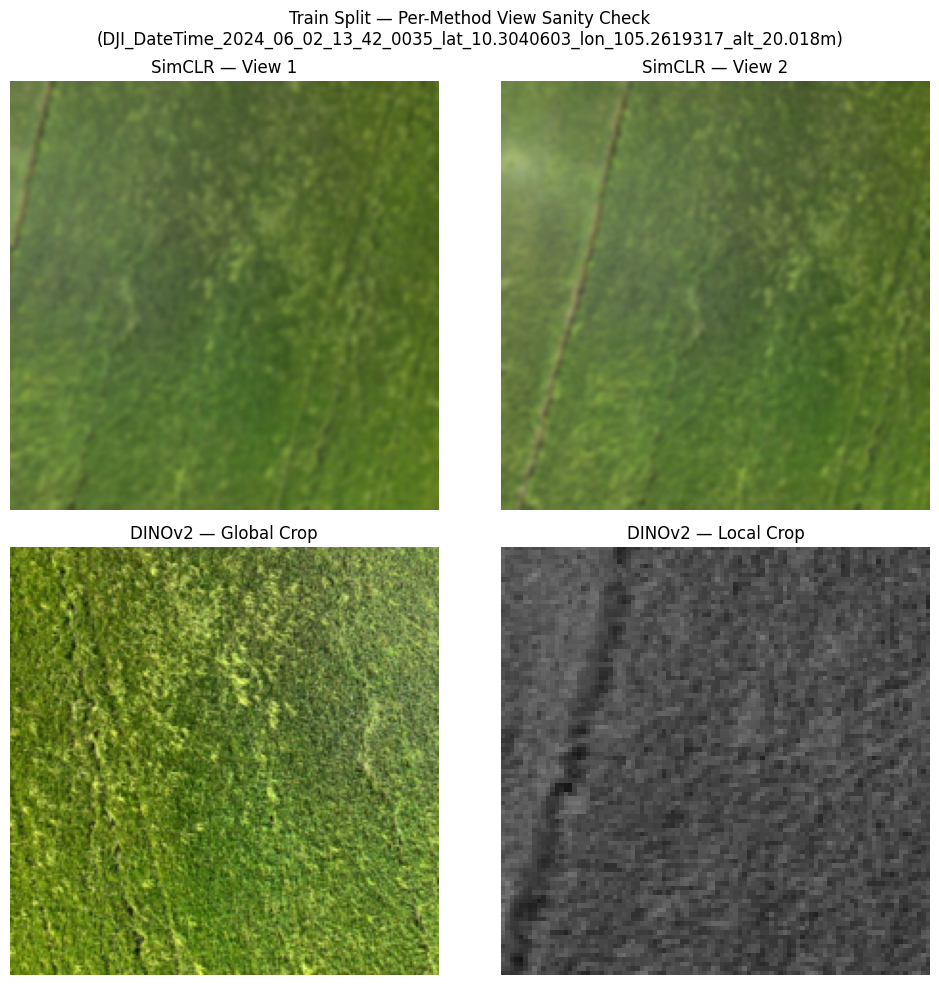

In [9]:
# ============================================================
# CELL 7 : Sanity Check — Per-Method Two-View Comparison
# ============================================================

def denormalize(t):
    t = t.clone()
    for c in range(3):
        t[c] = t[c] * STD[c] + MEAN[c]
    return t.clamp(0, 1).permute(1, 2, 0).numpy()

sample_stem = train_stems[0]

simclr_v1, simclr_v2 = simclr_two_views(sample_stem)
dino_globals, dino_locals = dino_multi_crop(sample_stem)

fig, axes = plt.subplots(2, 2, figsize=(10, 10))

axes[0, 0].imshow(denormalize(simclr_v1)); axes[0, 0].set_title("SimCLR — View 1"); axes[0, 0].axis("off")
axes[0, 1].imshow(denormalize(simclr_v2)); axes[0, 1].set_title("SimCLR — View 2"); axes[0, 1].axis("off")
axes[1, 0].imshow(denormalize(dino_globals[0])); axes[1, 0].set_title("DINOv2 — Global Crop"); axes[1, 0].axis("off")
axes[1, 1].imshow(denormalize(dino_locals[0])); axes[1, 1].set_title("DINOv2 — Local Crop"); axes[1, 1].axis("off")

plt.suptitle(f"Train Split — Per-Method View Sanity Check\n({sample_stem})")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "sanity_train_per_method_views.png", dpi=150, bbox_inches="tight")
plt.show()

## Cell 8 — Sanity Check (b): Transformed Validation Image + Mask Overlay

**Objective:** Verify `val_finetune_transform` applies **synchronized** geometric
augmentation to image and mask together — not just that a raw pair is aligned.
The transformed tensor is de-normalized back to a displayable image so flips,
rotation, and boundary alignment can be visually confirmed after augmentation.

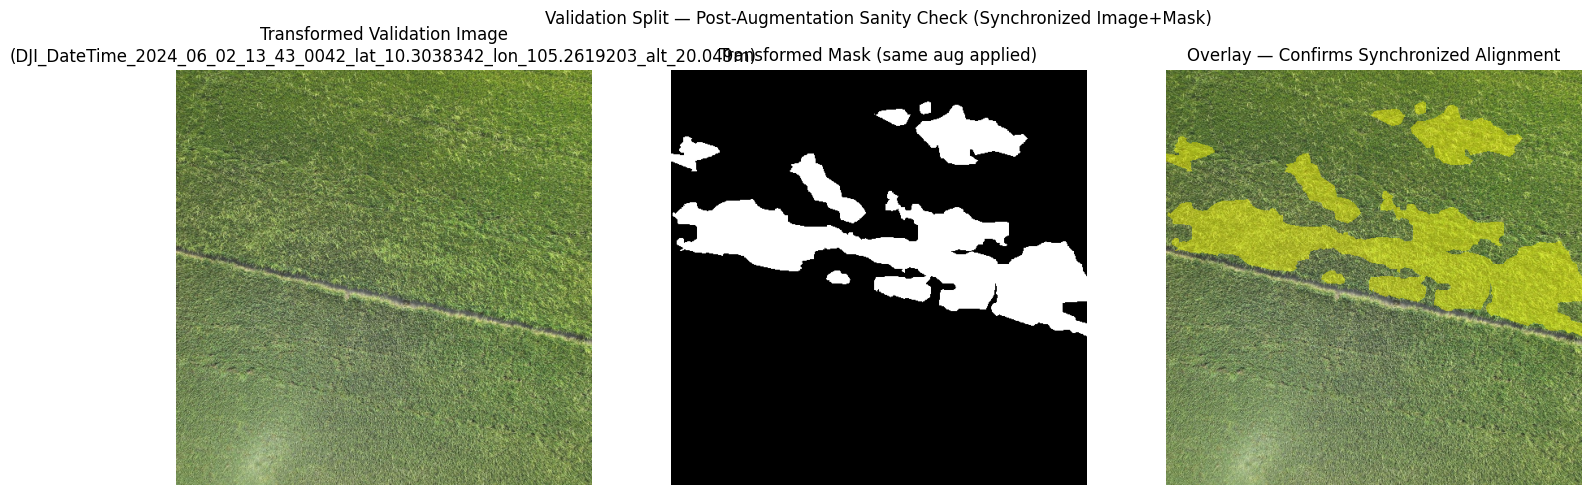

In [10]:
# ============================================================
# CELL 8 : Sanity Check — Transformed Validation Image + Mask Overlay
# ============================================================

val_stem = val_stems[0]
raw_img = np.array(Image.open(rgb_map[val_stem]).convert("RGB"))
raw_mask = np.array(Image.open(mask_map[val_stem]).convert("L"))
raw_mask = np.where(raw_mask > 0, 1, 0).astype(np.uint8)

aug = val_finetune_transform(image=raw_img, mask=raw_mask)
aug_img_tensor = aug["image"]        # normalized [C,H,W] tensor
aug_mask = aug["mask"].numpy()       # [H,W] array, values {0,1}

aug_img_display = denormalize(aug_img_tensor)  # de-normalized for display

overlay = (aug_img_display * 255).astype(np.uint8).copy()
yellow = np.array([255, 255, 0], dtype=np.uint8)
alpha = 0.45
fg = aug_mask > 0
overlay[fg] = (overlay[fg] * (1 - alpha) + yellow * alpha).astype(np.uint8)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(aug_img_display)
axes[0].set_title(f"Transformed Validation Image\n({val_stem})")
axes[0].axis("off")
axes[1].imshow(aug_mask, cmap="gray")
axes[1].set_title("Transformed Mask (same aug applied)")
axes[1].axis("off")
axes[2].imshow(overlay)
axes[2].set_title("Overlay — Confirms Synchronized Alignment")
axes[2].axis("off")
plt.suptitle("Validation Split — Post-Augmentation Sanity Check (Synchronized Image+Mask)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "sanity_val_mask_overlay.png", dpi=150, bbox_inches="tight")
plt.show()

## Cell 9 — Summary

- Loaded the identical Part-A train / validation / test split, unmodified.
- Verified zero leakage across all three splits, and confirmed every image/mask
  pairing exists on disk.
- Mapped each split to its Part-B role: **train → unlabelled SSL pretraining
  corpus**, **validation → labelled fine-tuning set**, **test → downstream
  monitoring + final evaluation** (with the test split's documented double role,
  per Section 2 of the assignment).
- Saved the split file lists as `part_b_split_roles.json` in `/kaggle/working`,
  intended as a Kaggle output/dataset that every SSL-method notebook can reference.
- Defined **per-method train-split view-generation pipelines** for all four SSL
  methods (SimCLR, BYOL, MAE, DINOv2), plus the synchronized validation
  fine-tuning pipeline (reusing Part-A's augmentation) and the deterministic test
  pipeline — reusing Part-A's exact `train_transform` / `valid_transform`.
- Built and verified actual `Dataset`/`DataLoader` objects for every split and
  method, confirming batch shapes end-to-end.
- Sanity-checked: (a) two-view generation for SimCLR and DINOv2 side by side,
  (b) synchronized image+mask alignment on the validation split *after*
  augmentation is applied (de-normalized for display).

This exact role mapping, split, and per-method loader setup is reused identically
by **all four SSL method notebooks** (SimCLR, BYOL, MAE, DINOv2), so the
label-efficiency comparison in the Final Comparison notebook is apples-to-apples.

**Image counts:**

| Split | Count | Role |
|---|---|---|
| Train | 438 | Unlabelled SSL pretraining corpus |
| Validation | 148 | Labelled fine-tuning set |
| Test | 148 | Downstream monitoring + final evaluation |

**Loaders available for reuse by method notebooks:**

| Loader | Yields |
|---|---|
| `simclr_train_loader` | Two contrastive views per image |
| `byol_train_loader` | Two views (online/target) per image |
| `mae_train_loader` | Single view (patch masking done in MAE notebook) |
| `dino_train_loader` | 2 global crops + 4 local crops per image |
| `val_finetune_loader` | Image + mask, Part-A augmentation, for supervised fine-tuning |
| `test_eval_loader` | Image + mask, deterministic, for monitoring + final eval |